In [1]:
import pandas as pd
import json

def jsonl_to_csv(jsonl_path: str, csv_path: str):
    """
    Reads the original evaluation trace logs (JSONL format) and exports
    to the flattened CSV format needed for the baseline translation.
    """
    records = []
    with open(jsonl_path, 'r') as f:
        for line in f:
            data = json.loads(line)
            obs = data['observations']
            row = {}
            for srv_name, srv_data in obs['services'].items():
                srv_name = srv_name.replace('-', '_')
                for k, v in srv_data.items():
                    if isinstance(v, (int, float)):
                        row[f"service_{srv_name}_{k}"] = v
            for slink_name, slink_data in obs['slinks'].items():
                # slink_name is like '("frame-sampler", "frame-resizer")'
                parts = tuple(json.loads(p.replace("'", '"')) for p in slink_name.strip('()').split(', '))
                name = f"slink_{parts[0].replace('-', '_')}_to_{parts[1].replace('-', '_')}"
                for k, v in slink_data.items():
                    row[f"{name}_{k}"] = v
            for cluster_name, nodes in obs['clusters'].items():
                for node_ip, node_data in nodes.items():
                    ip_str = node_ip.replace('.', '_')
                    for k, v in node_data.items():
                        row[f"node_{cluster_name}_{ip_str}_{k}"] = v
            for vlink_name, vlink_data in obs['vlinks'].items():
                parts = tuple(json.loads(p.replace("'", '"')) for p in vlink_name.strip('()').split(', '))
                name = f"vlink_{parts[0].replace('.', '_')}_to_{parts[1].replace('.', '_')}"
                for k, v in vlink_data.items():
                    row[f"{name}_{k}"] = v
            
            # Calculate end-to-end latency
            row['e2e_latency'] = (
                row.get('service_frame_sampler_latency', 0) +
                row.get('slink_frame_sampler_to_frame_resizer_latency', 0) +
                row.get('service_frame_resizer_latency', 0) +
                row.get('slink_frame_resizer_to_object_detector_latency', 0) +
                row.get('service_object_detector_latency', 0)
            )

            # Calculate sum of replicas
            row['sum_replicas'] = (
                row.get('service_frame_sampler_replicas', 0) +
                row.get('service_frame_resizer_replicas', 0) +
                row.get('service_object_detector_replicas', 0)
            )

            records.append(row)
    
    df_json = pd.DataFrame(records)
    df_json.to_csv(csv_path, index=False)
    print(f"Converted {jsonl_path} to {csv_path} (Shape: {df_json.shape})")
    return df_json

def translate_to_ud(input_path: str, output_path: str):
    """
    Translates the original real_dataset_YYMMDD.csv file into the UD format 
    by mapping the correct node metrics and renaming columns.
    """
    df = pd.read_csv(input_path)
    ud_df = df.copy()

    # Map the node metrics to each of the 3 services
    services = ["service_frame_sampler", "service_frame_resizer", "service_object_detector"]
    for s in services:
        ud_df[f"{s}_node_cpu_usage"] = df['node_member1_192_168_3_24_cpu_usage']
        ud_df[f"{s}_node_power_consumption"] = df['node_member1_192_168_3_24_power_consumption']

    # Map the vlink to slink nets
    # As observed, both slinks correspond to the same underlying physical vlink mapped in the dataset
    ud_df['slink_frame_sampler_to_frame_resizer_net_latency'] = df['vlink_192_168_3_24_to_10_0_2_35_net_latency']
    ud_df['slink_frame_resizer_to_object_detector_net_latency'] = df['vlink_192_168_3_24_to_10_0_2_35_net_latency']

    # Keep only the translated columns in the correct logical order
    cols_to_keep = []
    for s in services:
        cols_to_keep.extend([
            f"{s}_replicas", f"{s}_arrival_rate", f"{s}_completion_rate", 
            f"{s}_latency", f"{s}_cpu_usage", f"{s}_power_consumption", 
            f"{s}_node_cpu_usage", f"{s}_node_power_consumption"
        ])
    cols_to_keep.extend([
        'slink_frame_sampler_to_frame_resizer_latency', 'slink_frame_sampler_to_frame_resizer_net_latency', 
        'slink_frame_resizer_to_object_detector_latency', 'slink_frame_resizer_to_object_detector_net_latency',
        'e2e_latency', 'sum_replicas'
    ])
    
    ud_df = ud_df[cols_to_keep]
    ud_df.to_csv(output_path, index=False)
    print(f"Saved UD dataset to {output_path} (Shape: {ud_df.shape})")
    return ud_df

def create_scaling_biased_dataset(ud_df: pd.DataFrame, bd_output_path: str, ud_minus_bd_output_path: str):
    """
    Samples UD to create a Scaling Biased dataset (BD) and unobserved OOD set (UD \ BD).
    This restricts the state space to hide specific counterfactuals 
    (by applying a strict scaling policy: high replicas only under high arrival rate).
    """
    # Create BD by applying a strongly biased threshold-based autoscaling rule 
    cond_rep_1 = (ud_df['service_object_detector_replicas'] == 1) & (ud_df['service_frame_sampler_arrival_rate'] <= 10.0)
    cond_rep_2 = (ud_df['service_object_detector_replicas'] == 2) & (ud_df['service_frame_sampler_arrival_rate'] > 10.0) & (ud_df['service_frame_sampler_arrival_rate'] <= 20.0)
    cond_rep_3 = (ud_df['service_object_detector_replicas'] == 3) & (ud_df['service_frame_sampler_arrival_rate'] > 20.0)
    
    bd_df = ud_df[cond_rep_1 | cond_rep_2 | cond_rep_3].copy()
    
    # Generate UD \ BD (mathematical set difference)
    # Merging with indicator and filtering the left_only rows
    merged = ud_df.merge(bd_df, how='left', indicator=True)
    ud_minus_bd_df = merged[merged['_merge'] == 'left_only'].drop('_merge', axis=1)

    bd_df.to_csv(bd_output_path, index=False)
    ud_minus_bd_df.to_csv(ud_minus_bd_output_path, index=False)
    
    print(f"Saved Scaling BD dataset to {bd_output_path} (Shape: {bd_df.shape})")
    print(f"Saved Scaling UD\\BD dataset to {ud_minus_bd_output_path} (Shape: {ud_minus_bd_df.shape})")
    return bd_df, ud_minus_bd_df

def create_timeout_biased_dataset(ud_df: pd.DataFrame, bd_output_path: str, ud_minus_bd_output_path: str, timeout_threshold: float = 2.0):
    """
    Creates a biased dataset by simulating request timeouts.
    Requests with e2e_latency greater than the threshold are dropped (simulating they were not logged).
    """
    bd_timeout_df = ud_df[ud_df['e2e_latency'] <= timeout_threshold].copy()
    
    # Generate UD \ BD (mathematical set difference)
    merged = ud_df.merge(bd_timeout_df, how='left', indicator=True)
    ud_minus_bd_timeout_df = merged[merged['_merge'] == 'left_only'].drop('_merge', axis=1)

    bd_timeout_df.to_csv(bd_output_path, index=False)
    ud_minus_bd_timeout_df.to_csv(ud_minus_bd_output_path, index=False)
    
    print(f"Saved Timeout BD dataset to {bd_output_path} (Shape: {bd_timeout_df.shape})")
    print(f"Saved Timeout UD\\BD dataset to {ud_minus_bd_output_path} (Shape: {ud_minus_bd_timeout_df.shape})")
    return bd_timeout_df, ud_minus_bd_timeout_df

date = "260320"
# Example execution (you can run this to recreate the files)
raw_jsonl_input = f"data/{date}/real_dataset.jsonl"
raw_csv_input = f"data/{date}/real_dataset.csv"
ud_output = f"data/{date}/services_real_dataset_ud.csv"

bd_scaling_output = f"data/{date}/services_real_dataset_bd_scaling.csv"
ood_scaling_output = f"data/{date}/services_real_dataset_ud-bd_scaling.csv"

bd_timeout_output = f"data/{date}/services_real_dataset_bd_timeout.csv"
ood_timeout_output = f"data/{date}/services_real_dataset_ud-bd_timeout.csv"

_ = jsonl_to_csv(raw_jsonl_input, raw_csv_input)
ud_df = translate_to_ud(raw_csv_input, ud_output)

bd_scaling_df, ud_minus_bd_scaling_df = create_scaling_biased_dataset(ud_df, bd_scaling_output, ood_scaling_output)
bd_timeout_df, ud_minus_bd_timeout_df = create_timeout_biased_dataset(ud_df, bd_timeout_output, ood_timeout_output, timeout_threshold=400.0)


Converted data/260320/real_dataset.jsonl to data/260320/real_dataset.csv (Shape: (1899, 26))
Saved UD dataset to data/260320/services_real_dataset_ud.csv (Shape: (1899, 30))
Saved Scaling BD dataset to data/260320/services_real_dataset_bd_scaling.csv (Shape: (466, 30))
Saved Scaling UD\BD dataset to data/260320/services_real_dataset_ud-bd_scaling.csv (Shape: (1433, 30))
Saved Timeout BD dataset to data/260320/services_real_dataset_bd_timeout.csv (Shape: (1270, 30))
Saved Timeout UD\BD dataset to data/260320/services_real_dataset_ud-bd_timeout.csv (Shape: (629, 30))


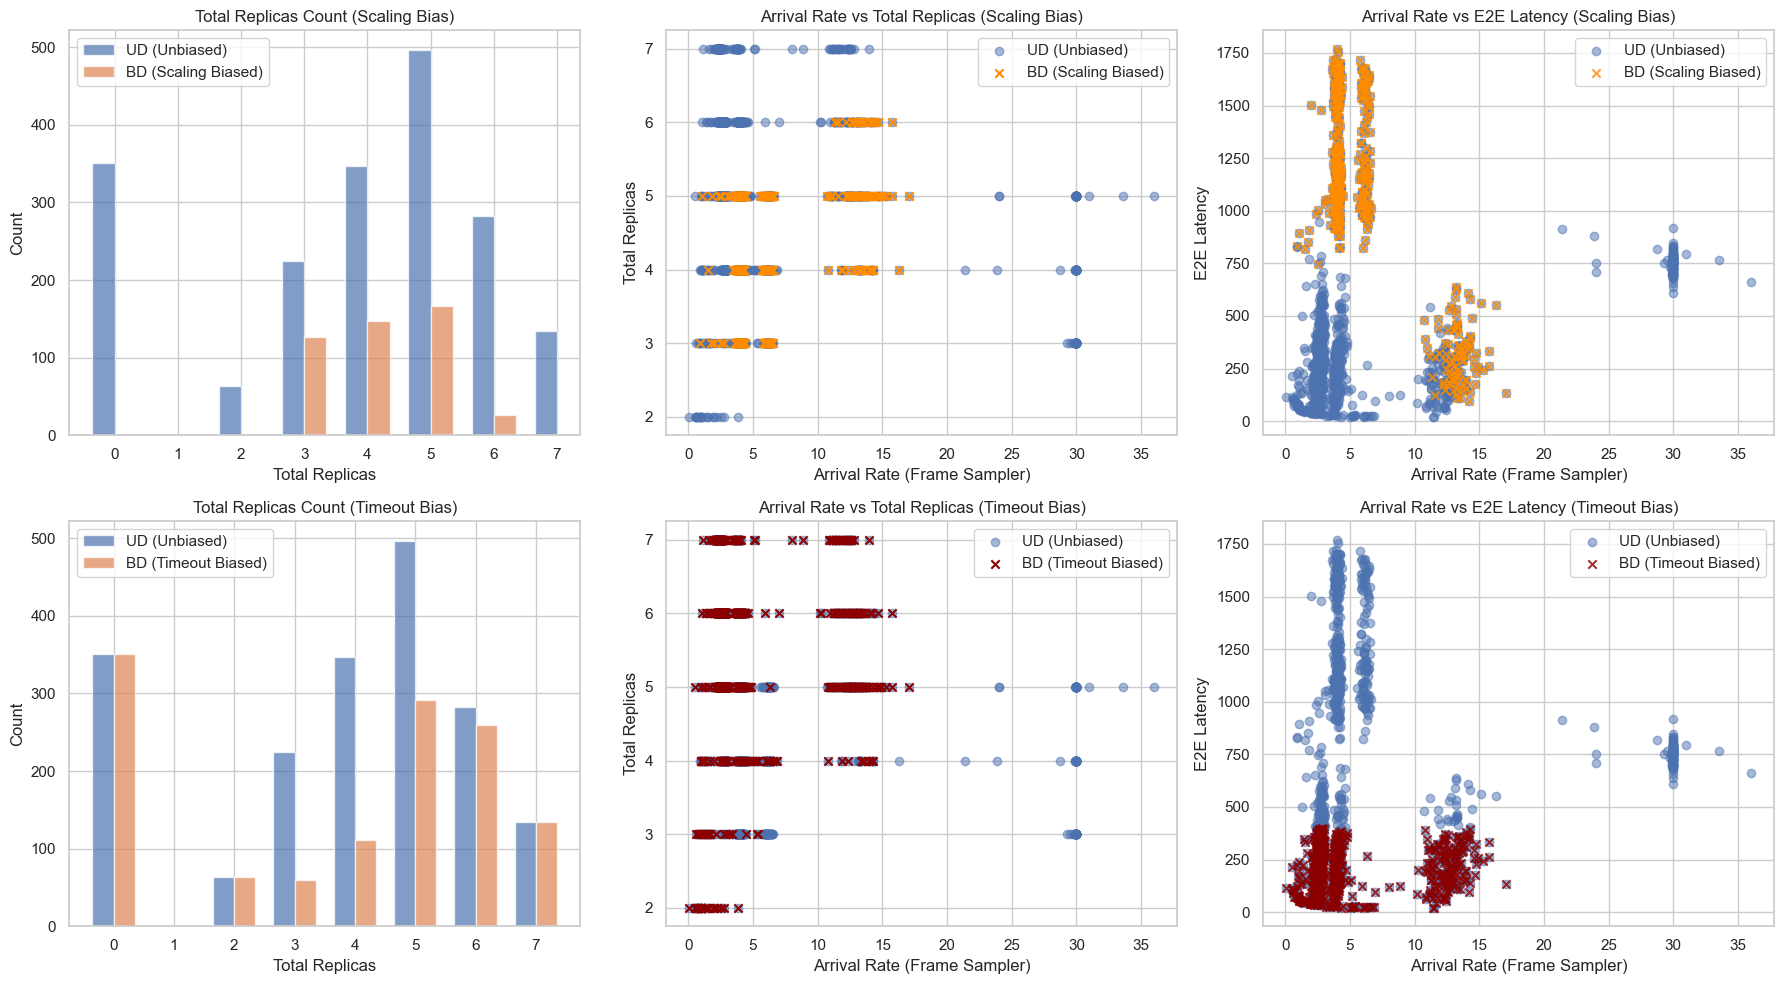

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for better visuals
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# --- SCALING BIAS (Top Row) ---
ud_counts = ud_df['sum_replicas'].value_counts().sort_index()
bd_scaling_counts = bd_scaling_df['sum_replicas'].value_counts().sort_index()

width = 0.35
axes[0, 0].bar(ud_counts.index - width/2, ud_counts.values, width, label='UD (Unbiased)', alpha=0.7)
axes[0, 0].bar(bd_scaling_counts.index + width/2, bd_scaling_counts.values, width, label='BD (Scaling Biased)', alpha=0.7)
axes[0, 0].set_title('Total Replicas Count (Scaling Bias)')
axes[0, 0].set_xlabel('Total Replicas')
axes[0, 0].set_ylabel('Count')
axes[0, 0].legend()

axes[0, 1].scatter(ud_df['service_frame_sampler_arrival_rate'], ud_df['sum_replicas'], alpha=0.5, label='UD (Unbiased)')
axes[0, 1].scatter(bd_scaling_df['service_frame_sampler_arrival_rate'], bd_scaling_df['sum_replicas'], alpha=1.0, label='BD (Scaling Biased)', marker='x', color='darkorange')
axes[0, 1].set_title('Arrival Rate vs Total Replicas (Scaling Bias)')
axes[0, 1].set_xlabel('Arrival Rate (Frame Sampler)')
axes[0, 1].set_ylabel('Total Replicas')
axes[0, 1].legend()

axes[0, 2].scatter(ud_df['service_frame_sampler_arrival_rate'], ud_df['e2e_latency'], alpha=0.5, label='UD (Unbiased)')
axes[0, 2].scatter(bd_scaling_df['service_frame_sampler_arrival_rate'], bd_scaling_df['e2e_latency'], alpha=0.8, label='BD (Scaling Biased)', marker='x', color='darkorange')
axes[0, 2].set_title('Arrival Rate vs E2E Latency (Scaling Bias)')
axes[0, 2].set_xlabel('Arrival Rate (Frame Sampler)')
axes[0, 2].set_ylabel('E2E Latency')
axes[0, 2].legend()

# --- TIMEOUT BIAS (Bottom Row) ---
bd_timeout_counts = bd_timeout_df['sum_replicas'].value_counts().sort_index()

axes[1, 0].bar(ud_counts.index - width/2, ud_counts.values, width, label='UD (Unbiased)', alpha=0.7)
axes[1, 0].bar(bd_timeout_counts.index + width/2, bd_timeout_counts.values, width, label='BD (Timeout Biased)', alpha=0.7)
axes[1, 0].set_title('Total Replicas Count (Timeout Bias)')
axes[1, 0].set_xlabel('Total Replicas')
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend()

axes[1, 1].scatter(ud_df['service_frame_sampler_arrival_rate'], ud_df['sum_replicas'], alpha=0.5, label='UD (Unbiased)')
axes[1, 1].scatter(bd_timeout_df['service_frame_sampler_arrival_rate'], bd_timeout_df['sum_replicas'], alpha=1.0, label='BD (Timeout Biased)', marker='x', color='darkred')
axes[1, 1].set_title('Arrival Rate vs Total Replicas (Timeout Bias)')
axes[1, 1].set_xlabel('Arrival Rate (Frame Sampler)')
axes[1, 1].set_ylabel('Total Replicas')
axes[1, 1].legend()

axes[1, 2].scatter(ud_df['service_frame_sampler_arrival_rate'], ud_df['e2e_latency'], alpha=0.5, label='UD (Unbiased)')
axes[1, 2].scatter(bd_timeout_df['service_frame_sampler_arrival_rate'], bd_timeout_df['e2e_latency'], alpha=0.8, label='BD (Timeout Biased)', marker='x', color='darkred')
axes[1, 2].set_title('Arrival Rate vs E2E Latency (Timeout Bias)')
axes[1, 2].set_xlabel('Arrival Rate (Frame Sampler)')
axes[1, 2].set_ylabel('E2E Latency')
axes[1, 2].legend()

plt.tight_layout()
plt.show()
